# 03 · Experiments: parameter sets and validation schemes

`02_modeling.ipynb` compared seven learners with **one** setting each (two of them tuned) under **one** validation scheme (repeated stratified 10-fold × 5) plus a single hold-out. This notebook covers the rest of Task 5 of the brief, *"different parameter sets and different validation schemes"*, in three parts:

- **A. Parameter sets.** Every learner is run over grids of its main hyperparameters on the **same 50 folds** as notebook 02, so every configuration can be compared fold by fold with the reference models (validation curves, best configuration per family, paired tests).
- **B. Validation schemes.** The reference models are evaluated with resubstitution, hold-out at four split ratios (100 random splits each), single 5- and 10-fold CV (20 shuffles each), repeated 10-fold × 5, leave-one-out and the bootstrap (out-of-bag and .632). For each scheme we look at the estimate it gives and how much it varies with the random split, and whether it would rank the models the same way.
- **C. Nested cross-validation.** Each learner is tuned by grid search *inside* each of the 50 outer folds. This gives an unbiased estimate of "tuned model" performance and measures how optimistic the non-nested "best of grid" score is.

Everything runs on the 734 training patients. The 184 test patients were used once in notebook 02 and are **not touched here**. Seed 42 throughout. Per-fold results are cached in `reports/experiments/cv_cache.pkl`, so re-running the notebook is quick.

In [1]:
import json
import os
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

# Silence convergence/deprecation warnings here and in the parallel workers (they inherit the environment)
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    get_scorer,
    make_scorer,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    LeaveOneOut,
    ParameterGrid,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    StratifiedShuffleSplit,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline

# Notebooks live in Analysis/notebooks, the package in Analysis/src
ANALYSIS = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "heart").is_dir())
sys.path.insert(0, str(ANALYSIS / "src"))
from heart import config as cfg
from heart.models import get_specs
from heart.preprocessing import build_preprocessor

DATA = ANALYSIS.parent / "Data" / "heart.csv"
RESULTS = ANALYSIS / "reports" / "experiments"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES = cfg.FIGURES
FIGURES.mkdir(parents=True, exist_ok=True)
print("analysis root:", ANALYSIS)

analysis root: C:\Users\ktran\Desktop\Εξορυξη\Project\Analysis


In [2]:
# Same split as 02_modeling.ipynb (heart.data.make_splits): 80/20, stratified on target x (Cholesterol == 0), seed 42.
# Re-implemented here so this notebook does not need great-expectations; the checks confirm it is the same split.
df = pd.read_csv(DATA)
X, y = df[cfg.FEATURE_COLS], df[cfg.TARGET]
strata = y.astype(str) + "_" + (df["Cholesterol"] == 0).astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=strata, random_state=cfg.SEED)

print("rows:", len(X_train), len(X_test))
print("disease rate:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("zero-chol share:", round((X_train["Cholesterol"] == 0).mean(), 3), round((X_test["Cholesterol"] == 0).mean(), 3))
assert (len(X_train), len(X_test)) == (734, 184)
del X_test, y_test  # the test set stays untouched in this notebook

rows: 734 184
disease rate: 0.553 0.554
zero-chol share: 0.187 0.19


## Shared setup

- **Metrics.** The seven metrics of notebook 02 plus **specificity**, **Cohen's kappa** and **MCC**, which the brief and Kumar et al. (2025) use and which were missing from the CV tables.
- **Folds.** `RepeatedStratifiedKFold(10, 5, seed 42)` on the same `X_train` gives exactly the 50 folds of notebook 02, so all configurations here are paired with the results there.
- **Paired test.** Nadeau–Bengio corrected t-interval over the 50 per-fold differences (copied from notebook 02). Holm's correction is applied where several models are tested against one reference.

In [3]:
SCORING = {
    "roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score",
    "accuracy": "accuracy", "recall": "recall",
    "specificity": make_scorer(recall_score, pos_label=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1", "kappa": make_scorer(cohen_kappa_score), "mcc": make_scorer(matthews_corrcoef),
}
METRICS = list(SCORING)
CV = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=cfg.SEED)  # the 50 folds of 02
N_SPLITS = 10

MODELS = ["logreg", "knn", "decision_tree", "random_forest", "xgboost", "lightgbm", "catboost"]
NAMES = {"logreg": "Logistic regression", "knn": "KNN", "decision_tree": "Decision tree",
         "random_forest": "Random forest", "xgboost": "XGBoost", "lightgbm": "LightGBM",
         "catboost": "CatBoost", "dummy_majority": "Majority baseline",
         "dummy_stratified": "Stratified baseline"}

CACHE_FILE = RESULTS / "cv_cache.pkl"
cache = pd.read_pickle(CACHE_FILE) if CACHE_FILE.exists() else {}


def save_cache():
    pd.to_pickle(cache, CACHE_FILE)


def to_frame(raw):
    """cross_validate output -> one row per fold, Brier back to 'lower is better'."""
    s = pd.DataFrame({k: v for k, v in raw.items() if k.startswith(("test_", "train_"))})
    brier = [c for c in s if c.endswith("_brier")]
    s[brier] *= -1
    return s


def run_cv(model, cv=CV, scoring=SCORING, key=None, train=True):
    """Cross-validate on the training set; results are cached under `key`."""
    if key is not None and key in cache:
        return cache[key]
    raw = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=train, n_jobs=-1)
    s = to_frame(raw)
    if key is not None:
        cache[key] = s
        save_cache()
    return s


def make(name, **params):
    """Pipeline of notebook 02 for `name`, with some estimator parameters overridden."""
    est, prep = get_specs()[name]
    return make_pipeline(build_preprocessor(**prep), clone(est).set_params(**params))


def params_key(model, params):
    return ("sweep", model, json.dumps(params, sort_keys=True, default=str))


def paired_stats(candidate, reference, lower_is_better=False):
    """Nadeau-Bengio corrected paired t-interval over per-fold differences (as in notebook 02)."""
    d = np.asarray(candidate, float) - np.asarray(reference, float)
    if lower_is_better:
        d = -d
    k = len(d)
    se = np.sqrt(d.var(ddof=1) * (1 / k + 1 / (N_SPLITS - 1)))
    if se == 0:
        return {"diff": d.mean(), "ci_low": d.mean(), "ci_high": d.mean(), "p": 1.0,
                "win_rate": (d > 0).mean()}
    t = d.mean() / se
    lo, hi = stats.t.interval(0.95, df=k - 1, loc=d.mean(), scale=se)
    return {"diff": d.mean(), "ci_low": lo, "ci_high": hi,
            "p": 2 * stats.t.sf(abs(t), df=k - 1), "win_rate": (d > 0).mean()}


def holm(pvalues):
    """Holm step-down adjusted p-values."""
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def verdict(lo, hi):
    return "better" if lo > 0 else "worse" if hi < 0 else "tied"


def summarise(frames, metrics=METRICS):
    rows = {}
    for name, s in frames.items():
        row = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in metrics}
        row["auc_gap"] = round(s["train_roc_auc"].mean() - s["test_roc_auc"].mean(), 3)
        rows[name] = row
    return pd.DataFrame(rows).T


def fmt(v):
    if v is None:
        return "None"
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        return f"{v:g}"
    return str(v)


# Plot style shared with notebook 02
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRID, INK, MUTED = "#d9d8d3", "#52514e", "#898781"
SERIES = [BLUE, ORANGE, AQUA]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "figure.dpi": 110,
})


def save_fig(name):
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

## Reference models (the settings of notebook 02), with the extra metrics

This re-runs the nine models of notebook 02 on the same folds. The ROC AUC of logistic regression must come out at 0.928 again; if it does, the folds and pipelines are identical.

In [4]:
start = time.time()
ref = {name: run_cv(make(name), key=("ref", name)) for name in get_specs()}
print(f"{time.time() - start:.0f}s")
REF_AUC = ref["logreg"]["test_roc_auc"].mean()
print("logistic regression ROC AUC:", round(REF_AUC, 4))
order = sorted(ref, key=lambda n: -ref[n]["test_roc_auc"].mean())
ref_table = summarise(ref).loc[order]
ref_table.to_csv(RESULTS / "reference_models.csv")
ref_table[["roc_auc", "accuracy", "recall", "specificity", "kappa", "mcc", "auc_gap"]]

0s
logistic regression ROC AUC: 0.9275


,roc_auc,accuracy,recall,specificity,kappa,mcc,auc_gap
logreg,0.928 ± 0.026,0.869 ± 0.033,0.902 ± 0.050,0.828 ± 0.058,0.734 ± 0.067,0.737 ± 0.066,0.01
random_forest,0.927 ± 0.027,0.869 ± 0.033,0.913 ± 0.048,0.814 ± 0.064,0.733 ± 0.069,0.738 ± 0.068,0.073
catboost,0.925 ± 0.027,0.871 ± 0.032,0.903 ± 0.048,0.830 ± 0.059,0.737 ± 0.066,0.740 ± 0.066,0.07
xgboost,0.924 ± 0.029,0.871 ± 0.038,0.899 ± 0.052,0.837 ± 0.067,0.738 ± 0.076,0.741 ± 0.076,0.068
knn,0.923 ± 0.030,0.867 ± 0.032,0.905 ± 0.046,0.820 ± 0.056,0.729 ± 0.066,0.733 ± 0.066,0.023
lightgbm,0.918 ± 0.030,0.862 ± 0.038,0.892 ± 0.055,0.825 ± 0.065,0.720 ± 0.077,0.723 ± 0.077,0.082
decision_tree,0.884 ± 0.039,0.837 ± 0.040,0.886 ± 0.062,0.776 ± 0.057,0.667 ± 0.080,0.672 ± 0.081,0.051
dummy_majority,0.500 ± 0.000,0.553 ± 0.005,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.0
dummy_stratified,0.493 ± 0.067,0.505 ± 0.067,0.607 ± 0.060,0.379 ± 0.075,-0.014 ± 0.136,-0.014 ± 0.137,0.006


# Part A · Parameter sets

Each **sweep** varies one hyperparameter (the x-axis), optionally crossed with a second one (the lines), while every other setting stays at the reference value of notebook 02. Every configuration is scored on the same 50 folds.

| Learner | Sweeps | Configurations |
|---|---|---|
| Logistic regression | `C` (10⁻³–10², 11 log-spaced values) × penalty mix `l1_ratio` ∈ {0 (L2), 0.5, 1 (L1)}, `saga` solver | 33 |
| KNN | `k` ∈ 1–91 × vote weighting (uniform, distance); `k` × distance metric (Euclidean `p=2`, Manhattan `p=1`) | 36 |
| Decision tree | `max_depth` 1–12 and unlimited × `min_samples_leaf` ∈ {1, 10, 30}; `max_depth` × split criterion (Gini, entropy) | 45 |
| Random forest | number of trees 10–800; `max_depth`; `max_features` (share of features per split); `min_samples_leaf` | 28 |
| XGBoost | rounds 25–1000 × learning rate {0.01, 0.05, 0.3}; tree depth 1–8; L2 penalty `reg_lambda` | 34 |
| LightGBM | rounds × learning rate; `num_leaves` 2–63; `min_child_samples` 5–80 | 32 |
| CatBoost | iterations × learning rate; symmetric-tree depth 1–8; `l2_leaf_reg` | 33 |

In [5]:
C_VALUES = [float(c) for c in np.round(np.logspace(-3, 2, 11), 4)]
K_VALUES = [1, 3, 5, 9, 15, 25, 41, 61, 91]
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 12, None]
ROUNDS = [25, 50, 100, 200, 300, 600, 1000]
RATES = [0.01, 0.05, 0.3]
LR_SAGA = {"solver": "saga", "max_iter": 5000}


def sweep(model, x, values, series=None, series_values=(None,), **fixed):
    configs = []
    for s in series_values:
        for v in values:
            params = {**fixed, x: v}
            if series is not None:
                params[series] = s
            configs.append(params)
    sid = f"{model}:{x}" + (f" x {series}" if series else "")
    return {"id": sid, "model": model, "x": x, "series": series, "configs": configs}


SWEEPS = [
    sweep("logreg", "C", C_VALUES, "l1_ratio", [0.0, 0.5, 1.0], **LR_SAGA),
    sweep("knn", "n_neighbors", K_VALUES, "weights", ["uniform", "distance"]),
    sweep("knn", "n_neighbors", K_VALUES, "p", [2, 1]),
    sweep("decision_tree", "max_depth", DEPTHS, "min_samples_leaf", [1, 10, 30]),
    sweep("decision_tree", "max_depth", DEPTHS, "criterion", ["gini", "entropy"]),
    sweep("random_forest", "n_estimators", [10, 25, 50, 100, 200, 300, 500, 800]),
    sweep("random_forest", "max_depth", [2, 3, 4, 5, 7, 10, 15, None]),
    sweep("random_forest", "max_features", [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]),
    sweep("random_forest", "min_samples_leaf", [1, 2, 5, 10, 20, 40]),
    sweep("xgboost", "n_estimators", ROUNDS, "learning_rate", RATES),
    sweep("xgboost", "max_depth", [1, 2, 3, 4, 6, 8]),
    sweep("xgboost", "reg_lambda", [0, 0.3, 1, 3, 10, 30, 100]),
    sweep("lightgbm", "n_estimators", ROUNDS, "learning_rate", RATES),
    sweep("lightgbm", "num_leaves", [2, 4, 8, 15, 31, 63]),
    sweep("lightgbm", "min_child_samples", [5, 10, 20, 40, 80]),
    sweep("catboost", "iterations", ROUNDS, "learning_rate", RATES),
    sweep("catboost", "depth", [1, 2, 3, 4, 6, 8]),
    sweep("catboost", "l2_leaf_reg", [0.3, 1, 3, 10, 30, 100]),
]
print(sum(len(s["configs"]) for s in SWEEPS), "configurations x 50 folds")

241 configurations x 50 folds


In [6]:
rows = []
for sw in SWEEPS:
    start = time.time()
    for params in sw["configs"]:
        key = params_key(sw["model"], params)
        s = run_cv(make(sw["model"], **params), key=key)
        rows.append({
            "model": sw["model"], "sweep": sw["id"], "key": key,
            "params": json.dumps(params, default=str),
            "x_value": fmt(params[sw["x"]]),
            "series_value": fmt(params[sw["series"]]) if sw["series"] else "",
            **{m: s[f"test_{m}"].mean() for m in METRICS},
            "roc_auc_sd": s["test_roc_auc"].std(),
            "train_roc_auc": s["train_roc_auc"].mean(),
        })
    print(f"{sw['id']:45s} {time.time() - start:6.1f}s")

sweep_df = pd.DataFrame(rows)
sweep_df["auc_gap"] = sweep_df["train_roc_auc"] - sweep_df["roc_auc"]
sweep_df.drop(columns="key").to_csv(RESULTS / "param_sweeps.csv", index=False)
print(sweep_df["params"].nunique(), "distinct configurations")

logreg:C x l1_ratio                              0.0s
knn:n_neighbors x weights                        0.0s
knn:n_neighbors x p                              0.0s


decision_tree:max_depth x min_samples_leaf       0.0s
decision_tree:max_depth x criterion              0.0s
random_forest:n_estimators                       0.0s
random_forest:max_depth                          0.0s
random_forest:max_features                       0.0s
random_forest:min_samples_leaf                   0.0s
xgboost:n_estimators x learning_rate             0.0s
xgboost:max_depth                                0.0s
xgboost:reg_lambda                               0.0s
lightgbm:n_estimators x learning_rate            0.0s
lightgbm:num_leaves                              0.0s
lightgbm:min_child_samples                       0.0s
catboost:iterations x learning_rate              0.0s
catboost:depth                                   0.0s
catboost:l2_leaf_reg                             0.0s


217 distinct configurations


## Validation curves

Mean validation ROC AUC over the 50 folds for each configuration. In panels with a single line, the dashed grey line is the mean **training** ROC AUC, so the distance between the two lines is the overfitting gap. The dotted line is logistic regression with its reference settings (0.928). The fold-to-fold standard deviation is about 0.026–0.03 for every configuration, so differences of a few thousandths are well within noise.

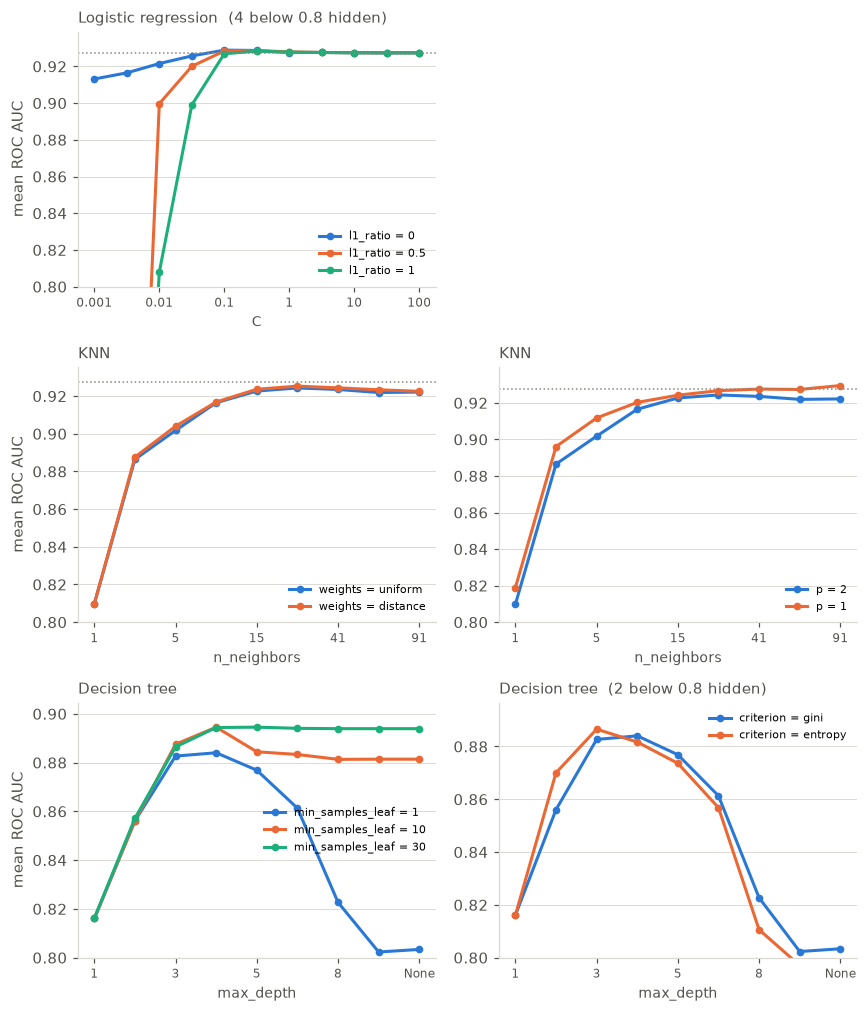

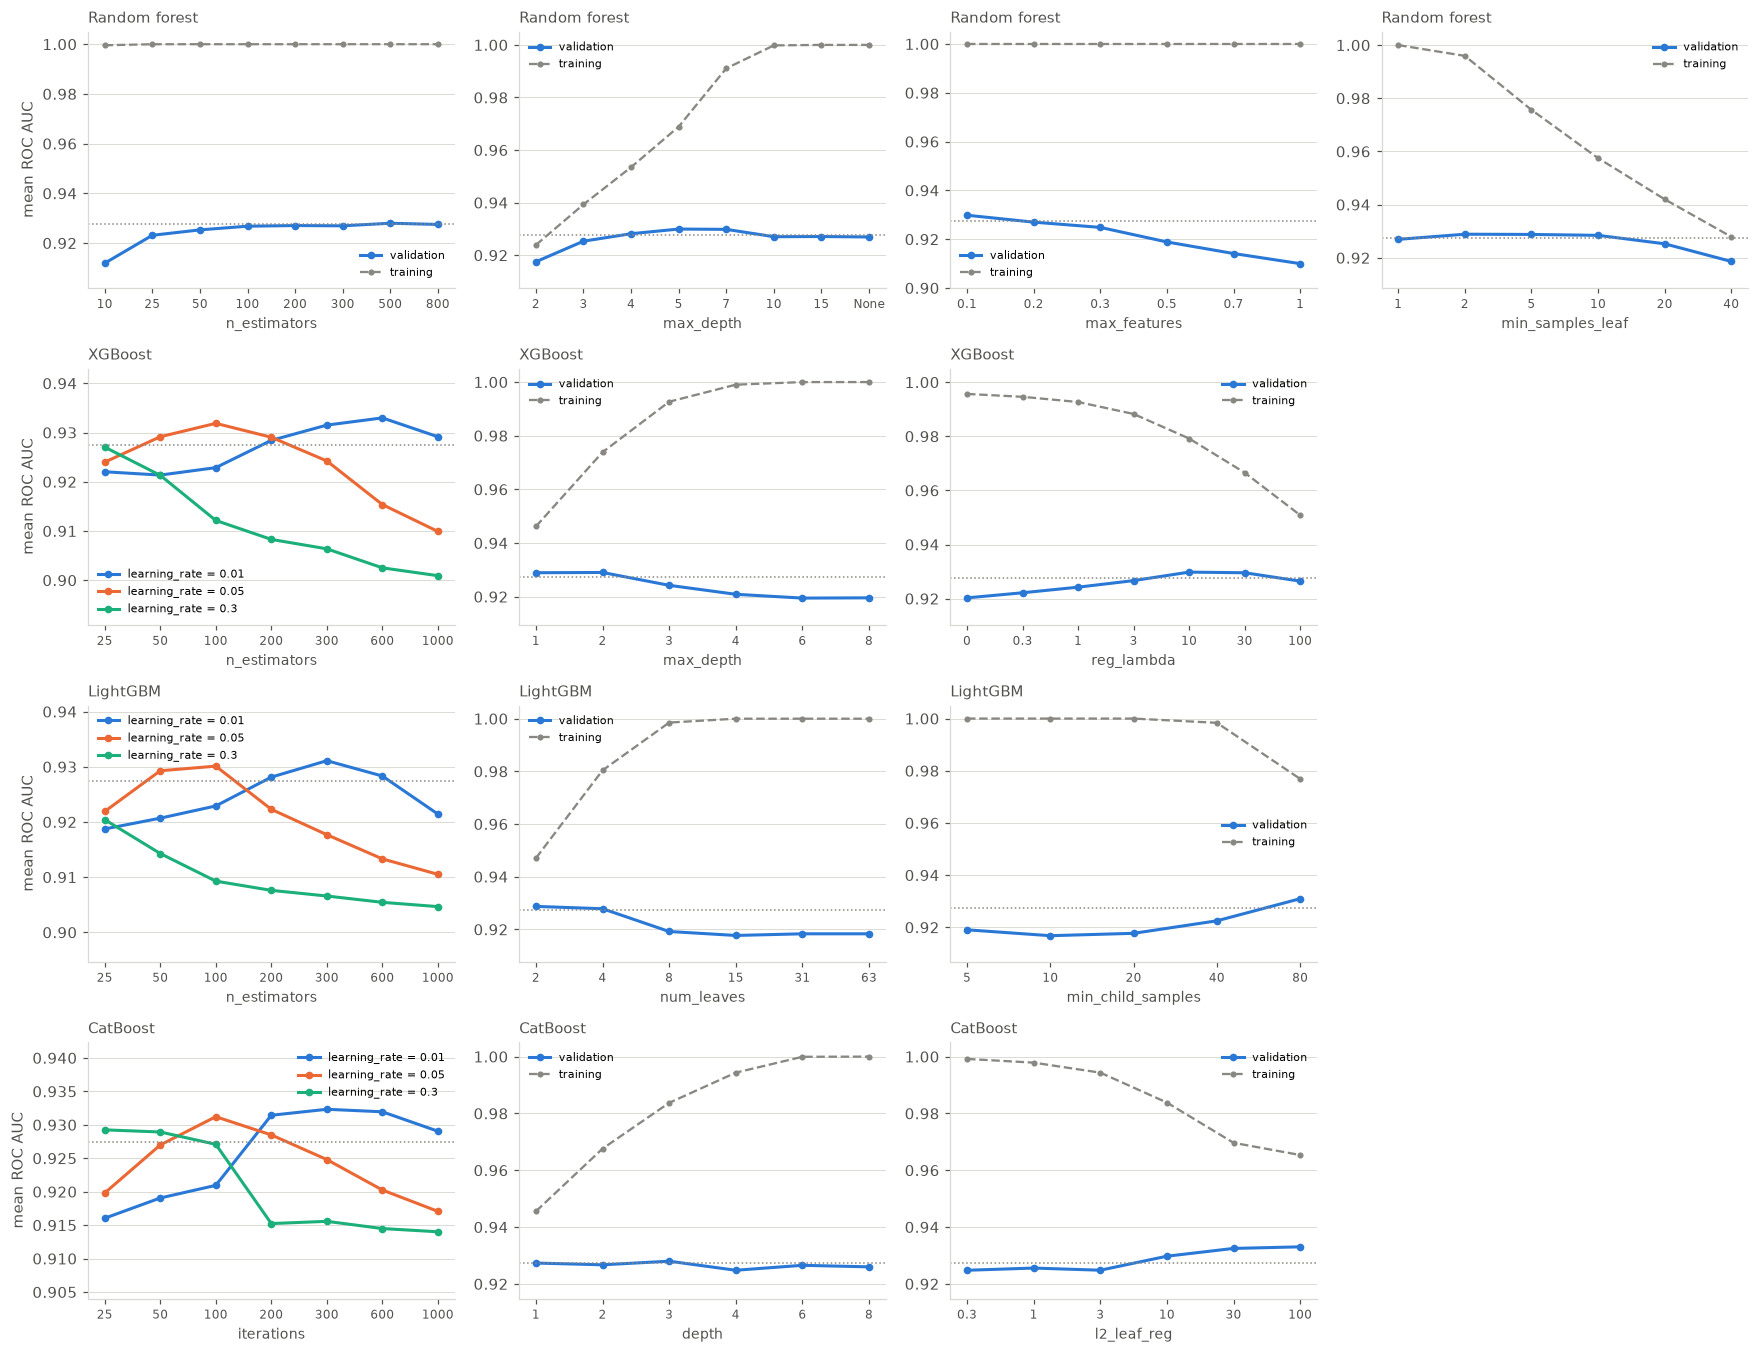

In [7]:
FLOOR = 0.80  # collapsed configurations (AUC ~0.5) would squash the axis


def plot_sweep(ax, sw):
    d = sweep_df[sweep_df["sweep"] == sw["id"]]
    xs = list(dict.fromkeys(d["x_value"]))
    pos = {v: i for i, v in enumerate(xs)}
    series = list(dict.fromkeys(d["series_value"]))
    for i, sv in enumerate(series):
        g = d[d["series_value"] == sv]
        label = f"{sw['series']} = {sv}" if sw["series"] else "validation"
        ax.plot([pos[v] for v in g["x_value"]], g["roc_auc"], color=SERIES[i], lw=2,
                marker="o", ms=4, label=label)
    if not sw["series"]:
        ax.plot([pos[v] for v in d["x_value"]], d["train_roc_auc"], color=MUTED, lw=1.5,
                ls="--", marker="o", ms=3, label="training")
    ax.axhline(REF_AUC, color=MUTED, lw=1, ls=":")
    hidden = int((d["roc_auc"] < FLOOR).sum())
    lo = max(FLOOR, d["roc_auc"].min() - 0.01)
    hi = 1.005 if not sw["series"] else d["roc_auc"].max() + 0.01
    ax.set_ylim(lo, hi)
    step = 2 if len(xs) > 8 else 1
    ax.set_xticks(range(0, len(xs), step), xs[::step], fontsize=8)
    ax.set_xlabel(sw["x"], fontsize=9)
    title = NAMES[sw["model"]] + (f"  ({hidden} below {FLOOR} hidden)" if hidden else "")
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.legend(frameon=False, fontsize=7, loc="best")
    ax.grid(axis="x", visible=False)


def sweep_figure(models, ncols, name):
    rows_ = [[sw for sw in SWEEPS if sw["model"] == m] for m in models]
    fig, axes = plt.subplots(len(rows_), ncols, figsize=(4 * ncols, 3.1 * len(rows_)), squeeze=False)
    for r, sws in enumerate(rows_):
        for c in range(ncols):
            if c < len(sws):
                plot_sweep(axes[r, c], sws[c])
            else:
                axes[r, c].set_visible(False)
        axes[r, 0].set_ylabel("mean ROC AUC")
    fig.tight_layout()
    save_fig(name)
    plt.show()


sweep_figure(["logreg", "knn", "decision_tree"], 2, "17_param_sweeps_simple")
sweep_figure(["random_forest", "xgboost", "lightgbm", "catboost"], 4, "18_param_sweeps_ensembles")

### Findings: validation curves

- **Logistic regression** is flat for `C` ≥ 0.1 (ROC AUC 0.927–0.929) whatever the penalty type, and its training–validation gap never exceeds 0.010. Only strong regularisation hurts: with a mostly-L1 penalty and `C` ≤ 0.003 every coefficient is zero and the model predicts a constant (AUC 0.5; 4 configurations hidden). The pure-L2 model degrades gracefully (0.913 at `C` = 0.001).
- **KNN** depends on `k` only: `k` = 1 memorises the training data (validation AUC 0.810, gap 0.19); the curve rises to a plateau of 0.922–0.929 from `k` ≈ 15 on. Manhattan distance is slightly better than Euclidean at large `k` (0.929 at `k` = 91). Distance weighting leaves the validation score unchanged but pushes the training AUC to ~1 (gap ≈ 0.075): memorisation without benefit.
- **Decision tree** has a clear optimum at depth 3–5 (0.88–0.895). Unlimited depth falls to 0.80 with a gap of 0.20 (textbook overfitting). A minimum leaf size of 30 makes depth irrelevant (plateau 0.894). The split criterion makes no systematic difference.
- **Random forest**: more than ~100 trees changes nothing. Limiting the trees (depth 4–7, minimum leaf 2–10) cuts the gap from 0.073 to 0.025–0.06 at the same validation AUC. Fewer features per split is better: 10 % of the features gives 0.930, all features (plain bagging) 0.910.
- **Boosters**: learning rate and number of rounds trade off. Each learning rate has its own optimum (0.3 at ~25 rounds, 0.05 at ~100, 0.01 at 300–600) and overfits after it. The reference settings (0.05, 300 rounds) are already past the optimum, which explains the lower reference score of LightGBM. Smaller trees (XGBoost depth 1–2, LightGBM 2–4 leaves, CatBoost depth 1–3) and stronger regularisation (`reg_lambda` 10–30, `l2_leaf_reg` 30–100, `min_child_samples` 80) improve the score and shrink the gap. Depth-1 boosting, an additive model without interactions, already reaches 0.927–0.929, the level of logistic regression: interactions add little on this data.

## Best configuration per learner

For each learner, the configuration with the highest mean validation ROC AUC across all its sweeps, compared on the same 50 folds with (a) its own reference setting and (b) logistic regression with reference settings. p-values against logistic regression are Holm-adjusted over the six learners.

**Caveat (winner's curse):** the best of 30+ configurations is selected and scored on the same folds, so its score is biased upwards. Part C measures this bias with nested cross-validation.

In [8]:
best_rows = []
for m in MODELS:
    d = sweep_df[sweep_df["model"] == m]
    b = d.loc[d["roc_auc"].idxmax()]
    s_best = cache[b["key"]]
    own = paired_stats(s_best["test_roc_auc"], ref[m]["test_roc_auc"])
    vs_lr = paired_stats(s_best["test_roc_auc"], ref["logreg"]["test_roc_auc"])
    best_rows.append({
        "model": m, "configs": d["params"].nunique(), "best params": b["params"],
        "ref AUC": ref[m]["test_roc_auc"].mean(), "best AUC": b["roc_auc"], "best AUC sd": b["roc_auc_sd"],
        "accuracy": b["accuracy"], "recall": b["recall"], "specificity": b["specificity"],
        "kappa": b["kappa"], "gap": b["auc_gap"], "ref gap": ref[m]["train_roc_auc"].mean() - ref[m]["test_roc_auc"].mean(),
        "d vs own ref": own["diff"], "own lo": own["ci_low"], "own hi": own["ci_high"], "own p": own["p"],
        "d vs LR": vs_lr["diff"], "LR lo": vs_lr["ci_low"], "LR hi": vs_lr["ci_high"], "LR p": vs_lr["p"],
    })
best_df = pd.DataFrame(best_rows).set_index("model")
mask = best_df.index != "logreg"
best_df.loc[mask, "LR p (Holm)"] = holm(best_df.loc[mask, "LR p"])
best_df["own verdict"] = [verdict(lo, hi) for lo, hi in zip(best_df["own lo"], best_df["own hi"])]
best_df["LR verdict"] = [verdict(lo, hi) for lo, hi in zip(best_df["LR lo"], best_df["LR hi"])]
best_df.to_csv(RESULTS / "best_per_learner.csv")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(best_df.round(4))

,configs,best params,ref AUC,best AUC,best AUC sd,accuracy,recall,specificity,kappa,gap,...,own lo,own hi,own p,d vs LR,LR lo,LR hi,LR p,LR p (Holm),own verdict,LR verdict
model,,,,,,,,,,,,,,,,,,,,,
logreg,33,"{""solver"": ""saga"", ""max_iter"": 5000, ""C"": 0.1, ""l1_ratio"": 0.0}",0.9275,0.9289,0.0255,0.8665,0.9020,0.8226,0.7285,0.0062,...,-0.0035,0.0062,0.5794,0.0013,-0.0035,0.0062,0.5794,NaN,tied,tied
knn,36,"{""n_neighbors"": 91, ""p"": 1}",0.9227,0.9295,0.0274,0.8719,0.9119,0.8225,0.7392,0.0033,...,-0.0051,0.0187,0.2559,0.0020,-0.0085,0.0124,0.7054,1.0000,tied,tied
decision_tree,45,"{""max_depth"": 5, ""min_samples_leaf"": 30}",0.8840,0.8945,0.0387,0.8254,0.8598,0.7829,0.6455,0.0298,...,-0.0154,0.0364,0.4186,-0.0330,-0.0516,-0.0143,0.0009,0.0052,tied,worse
random_forest,28,"{""max_depth"": 5}",0.9269,0.9300,0.0260,0.8703,0.9208,0.8079,0.7353,0.0389,...,-0.0028,0.0089,0.3043,0.0025,-0.0062,0.0111,0.5717,1.0000,tied,tied
xgboost,34,"{""n_estimators"": 600, ""learning_rate"": 0.01}",0.9242,0.9330,0.0269,0.8728,0.9079,0.8294,0.7412,0.0431,...,0.0027,0.0148,0.0056,0.0055,-0.0035,0.0144,0.2246,0.8985,better,tied
lightgbm,32,"{""n_estimators"": 300, ""learning_rate"": 0.01}",0.9177,0.9311,0.0295,0.8744,0.9168,0.8221,0.7441,0.0494,...,0.0041,0.0227,0.0057,0.0036,-0.0069,0.0141,0.4939,1.0000,better,tied
catboost,33,"{""l2_leaf_reg"": 100}",0.9248,0.9330,0.0263,0.8777,0.9183,0.8275,0.7508,0.0323,...,0.0002,0.0162,0.0441,0.0055,-0.0015,0.0125,0.1201,0.6007,better,tied


In [9]:
# How sensitive is each learner to its parameters? Spread of mean AUC over all its configurations
# (configurations that collapse to a constant prediction excluded).
sens = (sweep_df[sweep_df["roc_auc"] > 0.6].groupby("model")["roc_auc"]
        .agg(["count", "min", "median", "max"]).loc[MODELS])
sens["range"] = sens["max"] - sens["min"]
sens["n collapsed"] = sweep_df[sweep_df["roc_auc"] <= 0.6].groupby("model").size().reindex(MODELS).fillna(0).astype(int)
# Configurations within 0.005 AUC of the learner's best
sens["within 0.005 of best"] = [
    (sweep_df[(sweep_df["model"] == m)]["roc_auc"] >= sens.loc[m, "max"] - 0.005).sum() for m in MODELS]
sens.round(4)

,count,min,median,max,range,n collapsed,within 0.005 of best
model,,,,,,,
logreg,29,0.8080,0.9274,0.9289,0.1209,4,22
knn,36,0.8098,0.9220,0.9295,0.1197,0,5
decision_tree,45,0.7922,0.8736,0.8945,0.1023,0,7
random_forest,28,0.9100,0.9269,0.9300,0.0200,0,20
xgboost,34,0.9009,0.9241,0.9330,0.0321,0,11
lightgbm,32,0.9047,0.9191,0.9311,0.0264,0,8
catboost,33,0.9140,0.9265,0.9330,0.0190,0,11


In [10]:
# Key readings from the sweeps, printed so the commentary can be checked against them
def row(model, **params):
    d = sweep_df[sweep_df["model"] == model]
    for k, v in params.items():
        d = d[d["params"].apply(lambda p, k=k: json.loads(p).get(k, "__missing__")) == v]
    return d[["sweep", "params", "roc_auc", "accuracy", "recall", "kappa", "train_roc_auc", "auc_gap"]]

with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(row("knn", weights="distance").round(3))
    display(sweep_df[sweep_df["sweep"] == "decision_tree:max_depth x min_samples_leaf"]
            [["params", "roc_auc", "accuracy", "auc_gap"]].round(3))
    display(sweep_df[sweep_df["model"] == "random_forest"][["sweep", "params", "roc_auc", "accuracy", "auc_gap"]].round(3))
    for m in ["xgboost", "lightgbm", "catboost"]:
        d = sweep_df[sweep_df["sweep"].str.contains("x learning_rate") & (sweep_df["model"] == m)]
        display(d.pivot(index="series_value", columns="x_value", values="roc_auc")
                [[fmt(r) for r in ROUNDS]].round(3).rename_axis(f"{m}: lr \\ rounds"))
    display(sweep_df[sweep_df["model"] == "logreg"].pivot(index="series_value", columns="x_value", values="roc_auc")
            [[fmt(c) for c in C_VALUES]].round(3).rename_axis("logreg: l1_ratio \\ C"))

,sweep,params,roc_auc,accuracy,recall,kappa,train_roc_auc,auc_gap
42,knn:n_neighbors x weights,"{""n_neighbors"": 1, ""weights"": ""distance""}",0.810,0.812,0.829,0.620,1.0,0.190
43,knn:n_neighbors x weights,"{""n_neighbors"": 3, ""weights"": ""distance""}",0.888,0.838,0.869,0.671,1.0,0.112
44,knn:n_neighbors x weights,"{""n_neighbors"": 5, ""weights"": ""distance""}",0.904,0.855,0.891,0.705,1.0,0.096
45,knn:n_neighbors x weights,"{""n_neighbors"": 9, ""weights"": ""distance""}",0.917,0.864,0.896,0.724,1.0,0.083
46,knn:n_neighbors x weights,"{""n_neighbors"": 15, ""weights"": ""distance""}",0.924,0.868,0.905,0.732,1.0,0.076
47,knn:n_neighbors x weights,"{""n_neighbors"": 25, ""weights"": ""distance""}",0.925,0.868,0.907,0.731,1.0,0.075
48,knn:n_neighbors x weights,"{""n_neighbors"": 41, ""weights"": ""distance""}",0.924,0.870,0.910,0.736,1.0,0.076
49,knn:n_neighbors x weights,"{""n_neighbors"": 61, ""weights"": ""distance""}",0.923,0.865,0.904,0.726,1.0,0.077
50,knn:n_neighbors x weights,"{""n_neighbors"": 91, ""weights"": ""distance""}",0.923,0.861,0.899,0.718,1.0,0.077


,params,roc_auc,accuracy,auc_gap
69,"{""max_depth"": 1, ""min_samples_leaf"": 1}",0.816,0.820,-0.000
70,"{""max_depth"": 2, ""min_samples_leaf"": 1}",0.856,0.822,0.023
71,"{""max_depth"": 3, ""min_samples_leaf"": 1}",0.883,0.839,0.029
72,"{""max_depth"": 4, ""min_samples_leaf"": 1}",0.884,0.837,0.051
73,"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.877,0.841,0.076
74,"{""max_depth"": 6, ""min_samples_leaf"": 1}",0.861,0.837,0.108
75,"{""max_depth"": 8, ""min_samples_leaf"": 1}",0.823,0.821,0.168
76,"{""max_depth"": 12, ""min_samples_leaf"": 1}",0.802,0.804,0.197
77,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.803,0.804,0.197
78,"{""max_depth"": 1, ""min_samples_leaf"": 10}",0.816,0.820,-0.000


,sweep,params,roc_auc,accuracy,auc_gap
114,random_forest:n_estimators,"{""n_estimators"": 10}",0.912,0.852,0.088
115,random_forest:n_estimators,"{""n_estimators"": 25}",0.923,0.862,0.077
116,random_forest:n_estimators,"{""n_estimators"": 50}",0.925,0.865,0.075
117,random_forest:n_estimators,"{""n_estimators"": 100}",0.927,0.870,0.073
118,random_forest:n_estimators,"{""n_estimators"": 200}",0.927,0.868,0.073
119,random_forest:n_estimators,"{""n_estimators"": 300}",0.927,0.869,0.073
120,random_forest:n_estimators,"{""n_estimators"": 500}",0.928,0.870,0.072
121,random_forest:n_estimators,"{""n_estimators"": 800}",0.927,0.870,0.073
122,random_forest:max_depth,"{""max_depth"": 2}",0.918,0.850,0.006
123,random_forest:max_depth,"{""max_depth"": 3}",0.925,0.857,0.014


x_value,25,50,100,200,300,600,1000
xgboost: lr \ rounds,,,,,,,
0.01,0.922,0.921,0.923,0.928,0.932,0.933,0.929
0.05,0.924,0.929,0.932,0.929,0.924,0.915,0.910
0.3,0.927,0.921,0.912,0.908,0.906,0.903,0.901


x_value,25,50,100,200,300,600,1000
lightgbm: lr \ rounds,,,,,,,
0.01,0.919,0.921,0.923,0.928,0.931,0.928,0.921
0.05,0.922,0.929,0.930,0.922,0.918,0.913,0.911
0.3,0.920,0.914,0.909,0.908,0.907,0.905,0.905


x_value,25,50,100,200,300,600,1000
catboost: lr \ rounds,,,,,,,
0.01,0.916,0.919,0.921,0.931,0.932,0.932,0.929
0.05,0.920,0.927,0.931,0.928,0.925,0.920,0.917
0.3,0.929,0.929,0.927,0.915,0.916,0.914,0.914


x_value,0.001,0.0032,0.01,0.0316,0.1,0.3162,1,3.1623,10,31.6228,100
logreg: l1_ratio \ C,,,,,,,,,,,
0,0.913,0.916,0.922,0.926,0.929,0.929,0.928,0.928,0.927,0.927,0.927
0.5,0.500,0.500,0.900,0.920,0.928,0.929,0.928,0.928,0.927,0.927,0.927
1,0.500,0.500,0.808,0.899,0.927,0.928,0.928,0.928,0.927,0.927,0.927


### Findings: best configuration per learner

- The best configuration of six learners lies between **0.929 and 0.933** ROC AUC; the best decision tree reaches 0.895.
- Against their **own reference settings**, only the three boosters improve significantly (XGBoost +0.009, LightGBM +0.013, CatBoost +0.008), all by moving to slower learning or stronger regularisation. Logistic regression, KNN, the tree and the forest are tied with their reference settings.
- Against **logistic regression**, no best configuration is significantly better (Holm-adjusted p ≥ 0.60). The decision tree stays significantly worse (−0.033, Holm p = 0.005).
- Logistic regression is the least sensitive learner: 22 of its 29 non-degenerate configurations are within 0.005 of its best. Accuracy and kappa follow the ROC AUC: kappa 0.73–0.75 for the six competitive learners at their best settings.

# Part B · Validation schemes

The same reference models are evaluated with every common validation scheme. For each scheme we record what **one** application of it would report (one hold-out split, one 10-fold run, one bootstrap resample), repeated over many random seeds, so we see both the estimate and how much it moves with the seed.

| Scheme | What one application is | Replicates |
|---|---|---|
| Resubstitution | train and score on all 734 patients | 1 (deterministic) |
| Hold-out 50/50, 70/30, 80/20, 90/10 | one stratified split | 100 random splits each |
| 5-fold CV, 10-fold CV | mean over the folds of one stratified k-fold run | 20 shuffles each |
| 10-fold CV × 5 | mean over 50 folds (the main scheme of this study) | 4 independent blocks of 5 repeats |
| LOOCV | 734 fits, each leaving one patient out; metrics on the pooled predictions | 1 (deterministic) |
| Bootstrap OOB | train on a bootstrap sample, score on the ~37 % out-of-bag patients | 100 resamples |
| Bootstrap .632 | 0.368 × training score + 0.632 × OOB score (Efron's correction) | 100 resamples |

All models see the same splits within a scheme, so differences between models are paired. The 80/20 hold-out on 734 patients leaves 147 validation patients, close to the 184-patient hold-out of Kumar et al. (2025) and of notebook 02.

In [11]:
SCHEME_METRICS = ["accuracy", "roc_auc", "recall", "kappa"]
SCHEME_SCORING = {m: SCORING[m] for m in SCHEME_METRICS}
N_REP = 100
HOLDOUTS = [0.5, 0.3, 0.2, 0.1]
SCHEMES = ["resubstitution"] + [f"hold-out {round((1 - t) * 100)}/{round(t * 100)}" for t in HOLDOUTS] + \
          ["5-fold CV", "10-fold CV", "10-fold CV × 5", "LOOCV", "bootstrap OOB", "bootstrap .632"]


def bootstrap_splits(n, n_boot, seed):
    rng = np.random.default_rng(seed)
    splits = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        splits.append((idx, np.setdiff1d(np.arange(n), idx)))
    return splits


BOOT = bootstrap_splits(len(y_train), N_REP, cfg.SEED)


def test_cols(s, prefix="test_"):
    return s[[prefix + m for m in SCHEME_METRICS]].set_axis(SCHEME_METRICS, axis=1)


def pooled_scores(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    return {"test_accuracy": accuracy_score(y_true, pred), "test_roc_auc": roc_auc_score(y_true, proba),
            "test_recall": recall_score(y_true, pred), "test_kappa": cohen_kappa_score(y_true, pred)}


estimates = []


def record(model, scheme, frame):
    for i, r in enumerate(frame.reset_index(drop=True).to_dict("records")):
        estimates.append({"model": model, "scheme": scheme, "rep": i, **{m: r[m] for m in SCHEME_METRICS}})


for m in MODELS:
    start = time.time()
    model = make(m)

    key = ("resub", m)
    if key not in cache:
        fitted = clone(model).fit(X_train, y_train)
        cache[key] = pd.DataFrame([{f"test_{k}": get_scorer(v)(fitted, X_train, y_train) if isinstance(v, str)
                                    else v(fitted, X_train, y_train) for k, v in SCHEME_SCORING.items()}])
        save_cache()
    record(m, "resubstitution", test_cols(cache[key]))

    for t in HOLDOUTS:
        s = run_cv(model, StratifiedShuffleSplit(N_REP, test_size=t, random_state=cfg.SEED), SCHEME_SCORING,
                   key=("holdout", t, m), train=False)
        record(m, f"hold-out {round((1 - t) * 100)}/{round(t * 100)}", test_cols(s))

    for k in [5, 10]:
        s = run_cv(model, RepeatedStratifiedKFold(n_splits=k, n_repeats=20, random_state=cfg.SEED),
                   SCHEME_SCORING, key=("kfold", k, m), train=False)
        t = test_cols(s)
        t["rep"] = np.arange(len(t)) // k
        per_run = t.groupby("rep")[SCHEME_METRICS].mean()
        record(m, f"{k}-fold CV", per_run)
        if k == 10:
            record(m, "10-fold CV × 5", per_run.groupby(per_run.index // 5).mean())

    key = ("loo", m)
    if key not in cache:
        proba = cross_val_predict(model, X_train, y_train, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        cache[key] = pd.DataFrame([pooled_scores(y_train, proba)])
        save_cache()
    record(m, "LOOCV", test_cols(cache[key]))

    s = run_cv(model, BOOT, SCHEME_SCORING, key=("boot", m), train=True)
    oob, tr = test_cols(s), test_cols(s, "train_")
    record(m, "bootstrap OOB", oob)
    record(m, "bootstrap .632", 0.368 * tr + 0.632 * oob)
    print(f"{m:15s} {time.time() - start:6.1f}s")

est_df = pd.DataFrame(estimates)
est_df.to_csv(RESULTS / "validation_scheme_estimates.csv", index=False)

logreg             0.0s
knn                0.0s
decision_tree      0.0s
random_forest      0.0s
xgboost            0.0s
lightgbm           0.0s
catboost           0.0s


## Estimate and spread per scheme

`mean` is the average over replicates (what the scheme reports on average); `sd` is how much a single application of the scheme varies with the random seed; `min`–`max` is the range a study could have reported by chance.

In [12]:
def scheme_table(metric):
    g = est_df.groupby(["scheme", "model"])[metric].agg(["mean", "std", "min", "max", "count"])
    return g.reindex(pd.MultiIndex.from_product([SCHEMES, MODELS], names=["scheme", "model"]))


def scheme_pivot(metric):
    t = scheme_table(metric)
    cell = t.apply(lambda r: f"{r['mean']:.3f}" + (f" ± {r['std']:.3f}" if r["count"] > 1 else ""), axis=1)
    return cell.unstack("model")[MODELS].loc[SCHEMES]


acc_table, auc_table = scheme_table("accuracy"), scheme_table("roc_auc")
acc_table.to_csv(RESULTS / "scheme_accuracy.csv")
auc_table.to_csv(RESULTS / "scheme_roc_auc.csv")
with pd.option_context("display.width", 250):
    print("Accuracy: mean ± sd of a single application")
    display(scheme_pivot("accuracy"))
    print("ROC AUC: mean ± sd of a single application")
    display(scheme_pivot("roc_auc"))
    print("Accuracy range (min - max) over replicates")
    display(acc_table.apply(lambda r: f"{r['min']:.3f}-{r['max']:.3f}", axis=1).unstack("model")[MODELS].loc[SCHEMES])

Accuracy: mean ± sd of a single application


model,logreg,knn,decision_tree,random_forest,xgboost,lightgbm,catboost
scheme,,,,,,,
resubstitution,0.873,0.876,0.886,1.000,0.951,1.000,0.962
hold-out 50/50,0.863 ± 0.015,0.865 ± 0.013,0.820 ± 0.022,0.866 ± 0.013,0.863 ± 0.015,0.858 ± 0.014,0.865 ± 0.014
hold-out 70/30,0.867 ± 0.019,0.866 ± 0.019,0.832 ± 0.022,0.869 ± 0.020,0.871 ± 0.017,0.864 ± 0.016,0.872 ± 0.018
hold-out 80/20,0.866 ± 0.026,0.865 ± 0.025,0.832 ± 0.031,0.868 ± 0.026,0.866 ± 0.025,0.859 ± 0.025,0.870 ± 0.025
hold-out 90/10,0.871 ± 0.035,0.869 ± 0.037,0.844 ± 0.043,0.871 ± 0.035,0.874 ± 0.038,0.864 ± 0.041,0.875 ± 0.038
5-fold CV,0.866 ± 0.004,0.867 ± 0.003,0.835 ± 0.006,0.869 ± 0.005,0.871 ± 0.005,0.862 ± 0.005,0.874 ± 0.005
10-fold CV,0.867 ± 0.004,0.866 ± 0.004,0.840 ± 0.007,0.869 ± 0.004,0.873 ± 0.003,0.862 ± 0.004,0.873 ± 0.004
10-fold CV × 5,0.867 ± 0.002,0.866 ± 0.001,0.840 ± 0.002,0.869 ± 0.001,0.873 ± 0.001,0.862 ± 0.001,0.873 ± 0.002
LOOCV,0.868,0.869,0.869,0.873,0.876,0.865,0.876


ROC AUC: mean ± sd of a single application


model,logreg,knn,decision_tree,random_forest,xgboost,lightgbm,catboost
scheme,,,,,,,
resubstitution,0.937,0.946,0.932,1.000,0.992,1.000,0.992
hold-out 50/50,0.924 ± 0.011,0.917 ± 0.010,0.858 ± 0.026,0.921 ± 0.010,0.919 ± 0.010,0.918 ± 0.010,0.922 ± 0.010
hold-out 70/30,0.926 ± 0.014,0.921 ± 0.015,0.878 ± 0.025,0.924 ± 0.014,0.924 ± 0.013,0.920 ± 0.013,0.924 ± 0.014
hold-out 80/20,0.924 ± 0.019,0.919 ± 0.022,0.880 ± 0.032,0.922 ± 0.022,0.921 ± 0.021,0.915 ± 0.022,0.922 ± 0.021
hold-out 90/10,0.928 ± 0.032,0.922 ± 0.029,0.892 ± 0.042,0.924 ± 0.032,0.924 ± 0.032,0.918 ± 0.033,0.925 ± 0.032
5-fold CV,0.926 ± 0.002,0.922 ± 0.002,0.881 ± 0.009,0.924 ± 0.002,0.924 ± 0.003,0.918 ± 0.003,0.924 ± 0.003
10-fold CV,0.927 ± 0.002,0.922 ± 0.002,0.886 ± 0.009,0.926 ± 0.002,0.925 ± 0.002,0.919 ± 0.002,0.926 ± 0.002
10-fold CV × 5,0.927 ± 0.001,0.922 ± 0.001,0.886 ± 0.005,0.926 ± 0.001,0.925 ± 0.000,0.919 ± 0.001,0.926 ± 0.001
LOOCV,0.926,0.922,0.874,0.925,0.924,0.919,0.926


Accuracy range (min - max) over replicates


model,logreg,knn,decision_tree,random_forest,xgboost,lightgbm,catboost
scheme,,,,,,,
resubstitution,0.873-0.873,0.876-0.876,0.886-0.886,1.000-1.000,0.951-0.951,1.000-1.000,0.962-0.962
hold-out 50/50,0.828-0.905,0.831-0.894,0.752-0.866,0.834-0.894,0.823-0.899,0.826-0.891,0.826-0.907
hold-out 70/30,0.805-0.914,0.824-0.928,0.760-0.887,0.805-0.919,0.814-0.914,0.819-0.905,0.824-0.914
hold-out 80/20,0.810-0.925,0.803-0.918,0.755-0.905,0.803-0.946,0.810-0.932,0.796-0.932,0.816-0.932
hold-out 90/10,0.757-0.932,0.770-0.959,0.730-0.932,0.757-0.959,0.784-0.946,0.770-0.946,0.784-0.973
5-fold CV,0.858-0.873,0.860-0.873,0.821-0.845,0.857-0.876,0.858-0.879,0.853-0.869,0.862-0.884
10-fold CV,0.858-0.873,0.860-0.871,0.824-0.853,0.861-0.877,0.866-0.879,0.856-0.872,0.867-0.880
10-fold CV × 5,0.864-0.870,0.865-0.867,0.837-0.843,0.868-0.871,0.871-0.874,0.862-0.864,0.871-0.876
LOOCV,0.868-0.868,0.869-0.869,0.869-0.869,0.873-0.873,0.876-0.876,0.865-0.865,0.876-0.876


## Would a single hold-out rank the models correctly?

On the main scheme (50 paired folds) the six competitive learners are statistically tied. Here we ask what a study that uses **one** 80/20 split would have concluded, over the 100 splits: which model would it have crowned, how large a difference between two tied models it could have reported, and how often the gap between the best and the worst of the six competitive learners would reach 3.8 points (the gap between the classical and quantum-inspired SVM of Kumar et al., 2025: 94.02 % vs 97.83 %).

In [13]:
competitive = [m for m in MODELS if m != "decision_tree"]
rank_rows = []
for sc in ["hold-out 80/20", "hold-out 90/10", "10-fold CV", "10-fold CV × 5", "bootstrap OOB"]:
    h = est_df[est_df["scheme"] == sc].pivot(index="rep", columns="model", values="accuracy")[competitive]
    winners = h.eq(h.max(axis=1), axis=0)
    share = winners.div(winners.sum(axis=1), axis=0).mean()
    spread = h.max(axis=1) - h.min(axis=1)
    diff = h["random_forest"] - h["logreg"]
    rank_rows.append({
        "scheme": sc, "replicates": len(h),
        **{f"P(best) {NAMES[m]}": share[m] for m in competitive},
        "RF-LR mean": diff.mean(), "RF-LR 2.5%": diff.quantile(0.025), "RF-LR 97.5%": diff.quantile(0.975),
        "best-worst median": spread.median(), "best-worst max": spread.max(),
        "P(best-worst >= 0.038)": (spread >= 0.038).mean(),
    })
rank_df = pd.DataFrame(rank_rows).set_index("scheme")
rank_df.to_csv(RESULTS / "scheme_rankings.csv")
with pd.option_context("display.width", 250):
    display(rank_df.round(3).T)

scheme,hold-out 80/20,hold-out 90/10,10-fold CV,10-fold CV × 5,bootstrap OOB
replicates,100.000,100.000,20.000,4.000,100.000
P(best) Logistic regression,0.197,0.171,0.050,0.000,0.200
P(best) KNN,0.133,0.206,0.050,0.000,0.083
P(best) Random forest,0.222,0.151,0.100,0.000,0.224
P(best) XGBoost,0.137,0.185,0.375,0.750,0.167
P(best) LightGBM,0.047,0.084,0.000,0.000,0.052
P(best) CatBoost,0.265,0.203,0.425,0.250,0.274
RF-LR mean,0.002,-0.000,0.002,0.002,0.001
RF-LR 2.5%,-0.038,-0.041,-0.007,-0.002,-0.026
RF-LR 97.5%,0.041,0.048,0.011,0.006,0.027


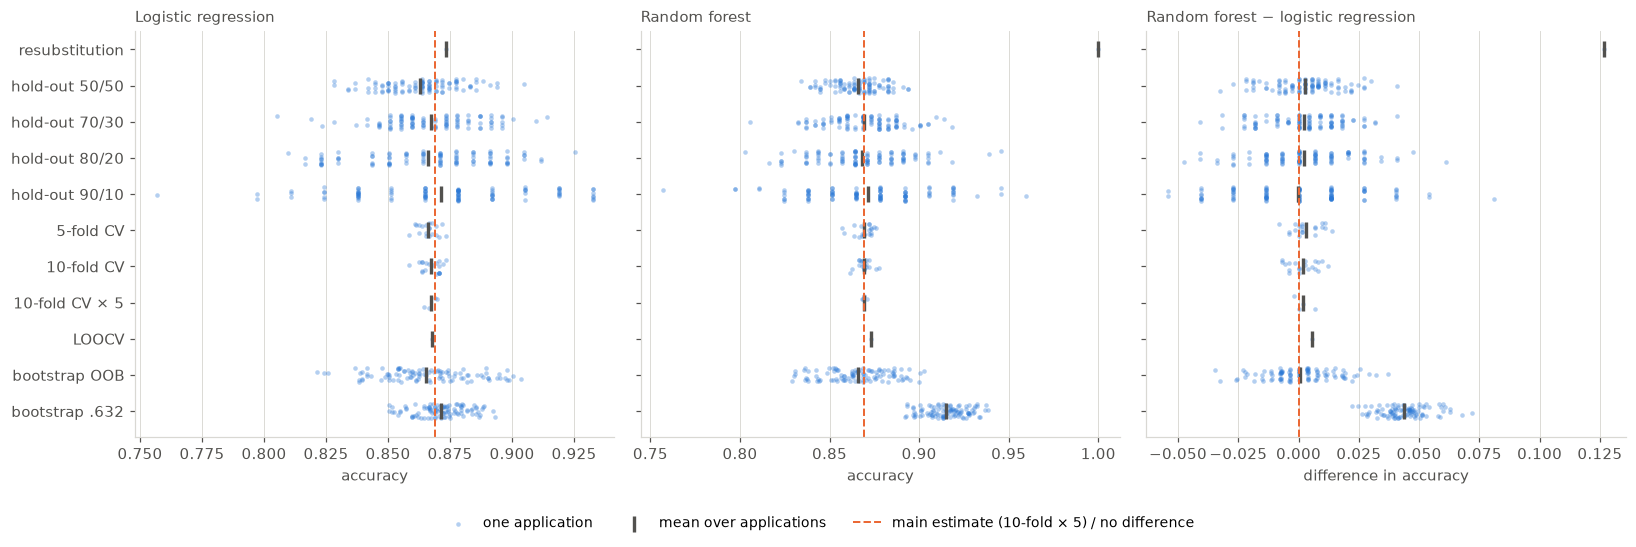

In [14]:
# Figure: every single estimate per scheme (accuracy) for logistic regression, random forest and their difference
rng = np.random.default_rng(cfg.SEED)


def scheme_values(model, scheme, metric="accuracy"):
    return est_df[(est_df["model"] == model) & (est_df["scheme"] == scheme)].sort_values("rep")[metric].to_numpy()


panels = [
    ("Logistic regression", lambda sc: scheme_values("logreg", sc), ref["logreg"]["test_accuracy"].mean()),
    ("Random forest", lambda sc: scheme_values("random_forest", sc), ref["random_forest"]["test_accuracy"].mean()),
    ("Random forest − logistic regression",
     lambda sc: scheme_values("random_forest", sc) - scheme_values("logreg", sc), 0.0),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
ypos = np.arange(len(SCHEMES))[::-1]
for ax, (title, values, anchor) in zip(axes, panels):
    for yp, sc in zip(ypos, SCHEMES):
        v = values(sc)
        jitter = rng.uniform(-0.2, 0.2, len(v)) if len(v) > 1 else np.zeros(1)
        ax.scatter(v, yp + jitter, s=9, color=BLUE, alpha=0.35, linewidths=0,
                   label="one application" if yp == ypos[0] else None)
        ax.scatter(v.mean(), yp, s=110, marker="|", color=INK, linewidths=2.2,
                   label="mean over applications" if yp == ypos[0] else None)
    ax.axvline(anchor, color=ORANGE, ls="--", lw=1.3,
               label="main estimate (10-fold × 5) / no difference" if ax is axes[0] else None)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel("accuracy" if anchor else "difference in accuracy")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, SCHEMES)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=3,
           loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig("19_validation_schemes")
plt.show()

### Findings: validation schemes

- **Resubstitution** is useless for flexible models: random forest and LightGBM score 100 % accuracy on their own training data, CatBoost 96 %, XGBoost 95 %. Logistic regression and KNN (87–88 %) are barely affected, so resubstitution would rank the models by capacity, not by quality (RF − LR = +12.7 points).
- **Hold-out** estimates are unbiased on average but noisy, and the noise grows as the test part shrinks: the standard deviation of a single accuracy estimate for logistic regression is 1.5 points at 50/50, 2.6 at 80/20 and 3.5 at 90/10. One 80/20 split could have reported anything from 81.0 % to 92.5 % (ROC AUC 0.88–0.97) for the same model; one 90/10 split anything from 75.7 % to 93.2 %.
- **k-fold CV** is far more stable: a single 5- or 10-fold run varies by about 0.4 points with the shuffle, and the repeated 10-fold × 5 estimate by about 0.2. Its mean agrees with the hold-out mean.
- **LOOCV** agrees with 10-fold CV for the stable learners (within 0.4 points) but not for the unstable decision tree (86.9 % vs 84.0 %). It gives a single number with no measure of its uncertainty and costs 734 fits per model.
- The **bootstrap OOB** estimate is slightly pessimistic (each model is trained on only ~63 % distinct patients), e.g. 86.5 % for logistic regression and 82.5 % for the tree. The **.632** correction fixes this for logistic regression (87.1 %), but it is strongly optimistic for the ensembles (random forest 91.5 %, boosters 90.8–91.2 %), because their training accuracy is close to 100 %. This is the known weakness of the .632 estimator for overfitting learners, and it again favours the ensembles spuriously (RF − LR = +4.4 points).
- **Ranking.** Under single 80/20 hold-outs, each of the six tied learners is "the best" in 5–27 % of the splits. The RF − LR difference ranges from −3.8 to +4.1 points (95 % of splits), and the best and worst of six tied learners differ by a median of 3.4 points. A gap of at least 3.8 points, as between the two SVMs of Kumar et al. (2025), appears in 37 % of 80/20 splits and in 75 % of 90/10 splits, although none of these learners differs significantly from another under repeated CV.

# Part C · Nested cross-validation

Selecting the best of many configurations on the same folds that score it (Part A, and the Optuna tuning of notebook 02) is optimistic. Nested CV removes this bias: in each of the **same 50 outer folds**, a grid search with an inner stratified 5-fold CV on the outer training part chooses the parameters, the chosen model is refitted on the outer training part and scored once on the outer validation fold. The outer scores are therefore paired with every other result in this notebook.

We compare three numbers per learner: the **reference** setting (no tuning), the **flat best of grid** (the same grid, best mean score on the 50 folds, optimistic), and the **nested** estimate (honest). Flat minus nested is the optimism of non-nested tuning.

In [15]:
GRIDS = {
    "logreg": {"C": C_VALUES, "l1_ratio": [0.0, 0.5, 1.0], **{k: [v] for k, v in LR_SAGA.items()}},
    "knn": {"n_neighbors": [5, 9, 15, 25, 41, 61], "weights": ["uniform", "distance"]},
    "decision_tree": {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 10, 30]},
    "random_forest": {"max_depth": [4, 7, None], "max_features": [0.2, 0.5], "min_samples_leaf": [1, 5]},
    "xgboost": {"learning_rate": [0.01, 0.05, 0.1], "n_estimators": [100, 300], "max_depth": [2, 3, 4]},
    "lightgbm": {"learning_rate": [0.01, 0.05, 0.1], "n_estimators": [100, 300], "num_leaves": [4, 8, 15]},
    "catboost": {"learning_rate": [0.03, 0.1], "iterations": [100, 300], "depth": [3, 4, 6]},
}
INNER = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.SEED)


def flat_best(m):
    """Every grid configuration on the 50 folds; the best mean ROC AUC (selection-biased)."""
    results = []
    for params in ParameterGrid(GRIDS[m]):
        s = run_cv(make(m, **params), key=params_key(m, params))
        results.append((s["test_roc_auc"].mean(), params, s))
    return max(results, key=lambda r: r[0])


def nested(m):
    key = ("nested", m)
    if key not in cache:
        pipe = make(m)
        step = pipe.steps[-1][0]
        search = GridSearchCV(pipe, {f"{step}__{p}": v for p, v in GRIDS[m].items()},
                              scoring="roc_auc", cv=INNER, n_jobs=1)
        raw = cross_validate(search, X_train, y_train, cv=CV, scoring=SCORING,
                             return_train_score=True, return_estimator=True, n_jobs=-1)
        chosen = [{k.split("__", 1)[1]: v for k, v in e.best_params_.items()} for e in raw["estimator"]]
        cache[key] = (to_frame(raw), chosen)
        save_cache()
    return cache[key]


nested_res, flat_res = {}, {}
for m in MODELS:
    start = time.time()
    flat_res[m] = flat_best(m)
    nested_res[m] = nested(m)
    print(f"{m:15s} grid {len(ParameterGrid(GRIDS[m])):3d}  {time.time() - start:6.1f}s")

logreg          grid  33     0.0s
knn             grid  12     0.0s
decision_tree   grid  18     0.0s
random_forest   grid  12     0.0s
xgboost         grid  18     0.0s
lightgbm        grid  18     0.0s
catboost        grid  12     0.0s


In [16]:
nest_rows = []
lr_nested = nested_res["logreg"][0]
for m in MODELS:
    s, chosen = nested_res[m]
    fb_auc, fb_params, fb_s = flat_res[m]
    vs_ref = paired_stats(s["test_roc_auc"], ref[m]["test_roc_auc"])
    vs_lr = paired_stats(s["test_roc_auc"], lr_nested["test_roc_auc"])
    common, count = Counter(json.dumps({k: fmt(v) for k, v in c.items() if k not in LR_SAGA}, sort_keys=True)
                            for c in chosen).most_common(1)[0]
    nest_rows.append({
        "model": m, "grid": len(ParameterGrid(GRIDS[m])),
        "ref AUC": ref[m]["test_roc_auc"].mean(), "flat best AUC": fb_auc,
        "nested AUC": s["test_roc_auc"].mean(), "nested AUC sd": s["test_roc_auc"].std(),
        "optimism": fb_auc - s["test_roc_auc"].mean(),
        "nested acc": s["test_accuracy"].mean(), "nested recall": s["test_recall"].mean(),
        "nested spec": s["test_specificity"].mean(), "nested kappa": s["test_kappa"].mean(),
        "nested mcc": s["test_mcc"].mean(),
        "nested gap": s["train_roc_auc"].mean() - s["test_roc_auc"].mean(),
        "d vs ref": vs_ref["diff"], "ref lo": vs_ref["ci_low"], "ref hi": vs_ref["ci_high"], "ref p": vs_ref["p"],
        "d vs nested LR": vs_lr["diff"], "nLR lo": vs_lr["ci_low"], "nLR hi": vs_lr["ci_high"], "nLR p": vs_lr["p"],
        "most chosen": common, "chosen share": count / len(chosen),
        "distinct choices": len({json.dumps(c, sort_keys=True, default=str) for c in chosen}),
    })
nest_df = pd.DataFrame(nest_rows).set_index("model")
mask = nest_df.index != "logreg"
nest_df.loc[mask, "nLR p (Holm)"] = holm(nest_df.loc[mask, "nLR p"])
nest_df["vs ref"] = [verdict(lo, hi) for lo, hi in zip(nest_df["ref lo"], nest_df["ref hi"])]
nest_df["vs nested LR"] = [verdict(lo, hi) if m != "logreg" else "" for m, lo, hi in
                           zip(nest_df.index, nest_df["nLR lo"], nest_df["nLR hi"])]
nest_df.to_csv(RESULTS / "nested_cv.csv")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(nest_df.round(4))

,grid,ref AUC,flat best AUC,nested AUC,nested AUC sd,optimism,nested acc,nested recall,nested spec,nested kappa,...,d vs nested LR,nLR lo,nLR hi,nLR p,most chosen,chosen share,distinct choices,nLR p (Holm),vs ref,vs nested LR
model,,,,,,,,,,,,,,,,,,,,,
logreg,33,0.9275,0.9289,0.9281,0.0259,0.0008,0.8711,0.9049,0.8293,0.7380,...,0.0000,0.0000,0.0000,1.0000,"{""C"": ""0.3162"", ""l1_ratio"": ""0.5""}",0.34,9,NaN,tied,
knn,12,0.9227,0.9253,0.9221,0.0285,0.0033,0.8687,0.9089,0.8189,0.7326,...,-0.0060,-0.0176,0.0056,0.3042,"{""n_neighbors"": ""15"", ""weights"": ""distance""}",0.26,6,1.0000,tied,tied
decision_tree,18,0.8840,0.8945,0.8953,0.0383,-0.0007,0.8303,0.8626,0.7902,0.6556,...,-0.0328,-0.0513,-0.0143,0.0008,"{""max_depth"": ""5"", ""min_samples_leaf"": ""30""}",0.24,9,0.0051,tied,worse
random_forest,12,0.9269,0.9308,0.9291,0.0268,0.0017,0.8701,0.9198,0.8085,0.7348,...,0.0010,-0.0068,0.0088,0.7974,"{""max_depth"": ""7"", ""max_features"": ""0.2"", ""min_samples_leaf"": ""1""}",0.34,6,1.0000,tied,tied
xgboost,18,0.9242,0.9319,0.9293,0.0284,0.0026,0.8695,0.9059,0.8244,0.7344,...,0.0013,-0.0071,0.0096,0.7651,"{""learning_rate"": ""0.1"", ""max_depth"": ""2"", ""n_estimators"": ""100""}",0.24,7,1.0000,tied,tied
lightgbm,18,0.9177,0.9322,0.9302,0.0283,0.0021,0.8727,0.9103,0.8263,0.7409,...,0.0021,-0.0072,0.0114,0.6499,"{""learning_rate"": ""0.01"", ""n_estimators"": ""300"", ""num_leaves"": ""8""}",0.30,9,1.0000,better,tied
catboost,12,0.9248,0.9313,0.9293,0.0270,0.0020,0.8750,0.9183,0.8214,0.7450,...,0.0012,-0.0058,0.0082,0.7330,"{""depth"": ""6"", ""iterations"": ""100"", ""learning_rate"": ""0.1""}",0.46,9,1.0000,tied,tied


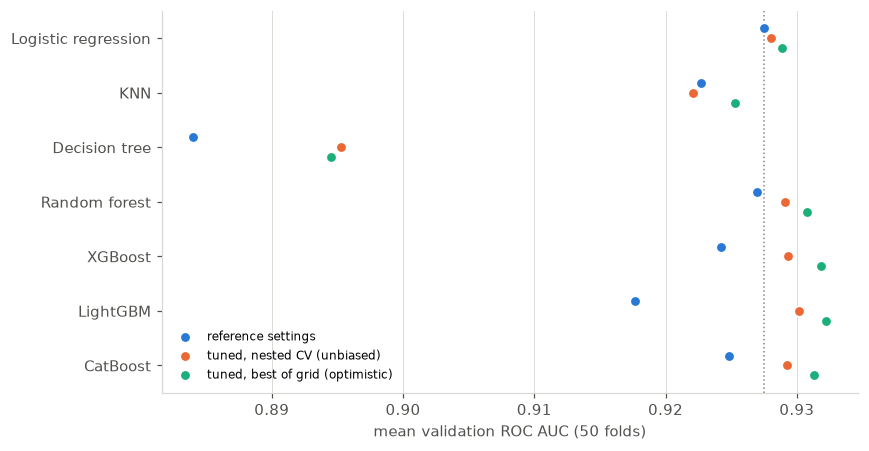

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.2))
yy = np.arange(len(MODELS))[::-1]
for i, (col, label) in enumerate([("ref AUC", "reference settings"),
                                  ("nested AUC", "tuned, nested CV (unbiased)"),
                                  ("flat best AUC", "tuned, best of grid (optimistic)")]):
    ax.scatter(nest_df.loc[MODELS, col], yy + (1 - i) * 0.18, s=46, color=SERIES[i], label=label, zorder=3,
               edgecolors="white", linewidths=1)
ax.axvline(REF_AUC, color=MUTED, ls=":", lw=1)
ax.set_yticks(yy, [NAMES[m] for m in MODELS])
ax.set_xlabel("mean validation ROC AUC (50 folds)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
save_fig("20_nested_cv")
plt.show()

### Findings: nested cross-validation

- Honestly tuned, six learners reach **0.928–0.930** ROC AUC and the decision tree 0.895. Accuracy is 86.9–87.5 % and kappa 0.73–0.75 for the six.
- The **optimism** of choosing the best grid configuration on the scoring folds is small: 0.001–0.003 ROC AUC. The grids lie on plateaus, so there is little to over-select. The non-nested Optuna scores of notebook 02 (0.929 and 0.931) are therefore not materially inflated.
- Against its own reference setting, nested tuning helps significantly only for **LightGBM** (+0.013), whose reference settings overfit. The others are tied.
- Against nested logistic regression, all learners are **tied** except the decision tree (−0.033, Holm p = 0.005).
- The chosen parameters are **unstable** across outer folds: the most frequent choice is picked in only 24–46 % of the 50 folds, with 6–9 distinct choices per learner. Many settings are equally good, which is the same plateau seen in the validation curves.

# Part D · Overall comparison

One row per learner, collecting what each part says. All columns except the hold-out range come from the same 50 folds.

In [18]:
h80 = est_df[est_df["scheme"] == "hold-out 80/20"]
overall = pd.DataFrame({
    "reference AUC": {m: ref[m]["test_roc_auc"].mean() for m in MODELS},
    "reference acc": {m: ref[m]["test_accuracy"].mean() for m in MODELS},
    "reference kappa": {m: ref[m]["test_kappa"].mean() for m in MODELS},
    "best-of-sweep AUC": best_df["best AUC"],
    "nested AUC": nest_df["nested AUC"],
    "nested acc": nest_df["nested acc"],
    "nested kappa": nest_df["nested kappa"],
    "LOOCV acc": acc_table.xs("LOOCV")["mean"],
    "80/20 hold-out acc min": h80.groupby("model")["accuracy"].min(),
    "80/20 hold-out acc max": h80.groupby("model")["accuracy"].max(),
}).loc[MODELS]
overall.to_csv(RESULTS / "overall_comparison.csv")
overall.round(3)

,reference AUC,reference acc,reference kappa,best-of-sweep AUC,nested AUC,nested acc,nested kappa,LOOCV acc,80/20 hold-out acc min,80/20 hold-out acc max
logreg,0.928,0.869,0.734,0.929,0.928,0.871,0.738,0.868,0.810,0.925
knn,0.923,0.867,0.729,0.929,0.922,0.869,0.733,0.869,0.803,0.918
decision_tree,0.884,0.837,0.667,0.895,0.895,0.830,0.656,0.869,0.755,0.905
random_forest,0.927,0.869,0.733,0.930,0.929,0.870,0.735,0.873,0.803,0.946
xgboost,0.924,0.871,0.738,0.933,0.929,0.870,0.734,0.876,0.810,0.932
lightgbm,0.918,0.862,0.720,0.931,0.930,0.873,0.741,0.865,0.796,0.932
catboost,0.925,0.871,0.737,0.933,0.929,0.875,0.745,0.876,0.816,0.932


# Conclusions

1. **Parameters matter within a learner, not between learners.** Badly chosen settings cost a lot: a 1-NN, an unpruned tree or a fully L1-penalised logistic regression lose 0.1–0.4 ROC AUC. Sensible settings form wide plateaus, and the best setting of every competitive learner ends up at 0.929–0.933 (0.928–0.930 when honestly nested), tied with logistic regression.
2. **What helps is restraint.** Every gain comes from limiting capacity: smaller trees, fewer features per split, slower learning, stronger penalties, larger neighbourhoods. The best settings also have the smallest training–validation gaps.
3. **The validation scheme matters more than the learner.** A single hold-out moves accuracy by ±2.5–3.5 points and crowns a different "best" model from split to split, which is larger than any real difference between the learners. Resubstitution and the .632 bootstrap reward overfitting. Repeated stratified k-fold CV with paired, corrected tests is the only scheme here that is both stable and unbiased.
4. **Model choice is unchanged:** logistic regression remains the recommended model (tied with the best, simplest, most stable), with the random forest as challenger. The test set was not used in this notebook.